# Avance 4. Modelos alternativos

**TC5035 Proyecto Integrador · Equipo 56**

Sistema Inteligente para la Optimización de Operaciones de Transporte mediante Inteligencia Artificial aplicada al Análisis Predictivo de Datos GPS (Feraltar).

| Integrante | Matrícula |
|---|---|
| Alejandra Guadalupe Larrañaga Altamirano | A01794334 |
| Mario Alberto Guillén | A01796701 |
| Andrea Kimberly Fray Tamayo | A01797168 |

**Objetivo de este avance:** construir al menos seis modelos individuales (no ensambles) con algoritmos variados para predecir la duración del viaje (`duration_seconds`), compararlos con un protocolo común, ajustar los hiperparámetros de los dos mejores y elegir el modelo individual final.

**Punto de partida (Avance 3).** El baseline de regresión lineal con Lasso obtuvo un MAE de 7.9 min en prueba, con 70 % de los viajes dentro de ±10 min. No sobreajusta, pero subajusta: los residuos muestran una relación no lineal con la distancia que una recta no captura. Los modelos de este avance buscan resolver ese subajuste.

**Contenido**
1. Configuración
2. Carga de la partición del Avance 2
3. Protocolo de evaluación
4. Referencias del Avance 3
5. Modelos alternativos
6. Tabla comparativa
7. Selección de los dos mejores modelos
8. Ajuste fino de hiperparámetros
9. Modelo individual final
10. Conclusiones
11. Bibliografía
12. Declaración sobre el uso de herramientas de inteligencia artificial

## 1. Configuración

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80)

SEMILLA = 42
OBJETIVO = "duration_seconds"
COLUMNA_DISTANCIA = "distance_km"

np.random.seed(SEMILLA)

## 2. Carga de la partición del Avance 2

Se usa la misma partición de entrenamiento y prueba exportada en el Avance 2 y usada en el Avance 3, para que todos los modelos se comparen sobre exactamente los mismos viajes.

In [2]:
def encontrar_raiz(inicio: Path) -> Path:
    for carpeta in [inicio, *inicio.parents]:
        if (carpeta / "data" / "processed").is_dir():
            return carpeta
    raise FileNotFoundError("No se encontró la carpeta data/processed en el repositorio.")


RAIZ = encontrar_raiz(Path.cwd())
PROCESADOS = RAIZ / "data" / "processed"
SUFIJO = "avance2.csv.gz"


def leer_y(nombre: str) -> pd.Series:
    datos = pd.read_csv(PROCESADOS / nombre)
    assert datos.shape[1] == 1, f"{nombre} debería tener una sola columna y tiene {datos.shape[1]}"
    return datos.iloc[:, 0]


X_train = pd.read_csv(PROCESADOS / f"X_train_{SUFIJO}")
X_test = pd.read_csv(PROCESADOS / f"X_test_{SUFIJO}")
y_train = leer_y(f"y_train_{SUFIJO}")
y_test = leer_y(f"y_test_{SUFIJO}")

assert y_train.name == OBJETIVO
assert list(X_train.columns) == list(X_test.columns)

print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")
print(f"Características: {X_train.shape[1]}")

X_train: (349445, 59) | X_test: (87362, 59)
Características: 59


## 3. Protocolo de evaluación

Para que la comparación sea justa, **todos los modelos se entrenan y evalúan con la misma función `registrar`**, que:

1. Entrena el modelo con el conjunto de entrenamiento y mide el **tiempo de entrenamiento**.
2. Predice el conjunto de prueba completo y mide el **tiempo de predicción**.
3. Calcula las métricas en entrenamiento y prueba, y guarda una fila en `resultados`.

**Métricas** (las mismas del Avance 3):

- **MAE en minutos, métrica principal.** Error promedio del ETA; la tabla comparativa se ordena por esta métrica.
- **RMSE en minutos.** Penaliza más los errores grandes, que son los más costosos para operaciones.
- **R².** Proporción de la variación de la duración explicada por el modelo.
- **% de viajes dentro de ±10 y ±15 min.** Lectura operativa del error.
- **Brecha de MAE (prueba menos entrenamiento).** Señal de sobreajuste.

**Modelos lentos.** Algunos algoritmos (por ejemplo SVR con kernel o KNN) escalan mal con 350 mil viajes. Para ellos se puede entrenar con una muestra usando `n_entrenamiento`; la evaluación **siempre** se hace sobre el conjunto de prueba completo, y la tabla registra cuántos viajes se usaron para entrenar.

In [3]:
resultados = []


def registrar(nombre, modelo, n_entrenamiento=None, columnas=None):
    """Entrena, mide tiempos y guarda las métricas de un modelo.

    nombre:          nombre del modelo en la tabla comparativa.
    modelo:          estimador de scikit-learn (o Pipeline) sin entrenar.
    n_entrenamiento: si se indica, entrena con una muestra aleatoria de ese tamaño.
    columnas:        si se indica, usa solo esas columnas (por defecto, las 59).
    """
    X_tr, y_tr = X_train, y_train
    if n_entrenamiento is not None and n_entrenamiento < len(X_train):
        idx = X_train.sample(n_entrenamiento, random_state=SEMILLA).index
        X_tr, y_tr = X_train.loc[idx], y_train.loc[idx]
    X_te = X_test
    if columnas is not None:
        X_tr, X_te = X_tr[columnas], X_te[columnas]

    inicio = time.perf_counter()
    modelo.fit(X_tr, y_tr)
    t_entrenamiento = time.perf_counter() - inicio

    inicio = time.perf_counter()
    pred_test = modelo.predict(X_te)
    t_prediccion = time.perf_counter() - inicio
    pred_train = modelo.predict(X_tr)

    error_test = np.abs(y_test.values - pred_test) / 60
    fila = {
        "modelo": nombre,
        "MAE_min": error_test.mean(),
        "RMSE_min": np.sqrt(mean_squared_error(y_test, pred_test)) / 60,
        "R2": r2_score(y_test, pred_test),
        "dentro_10min_%": (error_test <= 10).mean() * 100,
        "dentro_15min_%": (error_test <= 15).mean() * 100,
        "MAE_train_min": mean_absolute_error(y_tr, pred_train) / 60,
        "t_entrenamiento_s": t_entrenamiento,
        "t_prediccion_s": t_prediccion,
        "n_entrenamiento": len(X_tr),
    }
    fila["brecha_MAE_min"] = fila["MAE_min"] - fila["MAE_train_min"]

    resultados[:] = [r for r in resultados if r["modelo"] != nombre]
    resultados.append(fila)
    return pd.Series(fila).drop("modelo").round(3)

## 4. Referencias del Avance 3

Se vuelven a entrenar los dos modelos de referencia para que aparezcan en la tabla con sus tiempos:

- **Dummy (mediana):** piso, sin usar características.
- **Lasso (baseline del Avance 3):** con el `alpha` elegido por validación cruzada en el Avance 3 (0.001). Es el desempeño mínimo que deben superar los modelos alternativos.

Ninguno de los dos cuenta entre los seis modelos alternativos.

In [4]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Lasso

registrar("Ref. Dummy (mediana)", DummyRegressor(strategy="median"))
registrar("Ref. Lasso (baseline Avance 3)", Lasso(alpha=0.001, max_iter=2000, tol=1e-3))
pd.DataFrame(resultados).set_index("modelo")[["MAE_min", "RMSE_min", "R2", "dentro_10min_%", "t_entrenamiento_s"]].round(3)

,MAE_min,RMSE_min,R2,dentro_10min_%,t_entrenamiento_s
modelo,,,,,
Ref. Dummy (mediana),59.602,77.223,-0.050,9.630,0.029
Ref. Lasso (baseline Avance 3),7.934,10.273,0.981,70.298,5.972


## 5. Modelos alternativos

Se construyen seis modelos individuales con algoritmos de familias distintas. Todos usan la función `registrar` con sus hiperparámetros por defecto o razonables; el ajuste fino se hace en la sección 8 solo para los dos mejores.

| # | Modelo | Familia | Por qué se incluye |
|---|---|---|---|
| 5.1 | Regresión polinomial con Ridge | Lineal con transformación | Captura la curvatura entre distancia y duración que el baseline no modela |
| 5.2 | Árbol de decisión | Árboles | No lineal, interpretable y capta interacciones entre zona, hora y distancia |
| 5.3 | K vecinos más cercanos (KNN) | Basado en instancias | Predice con viajes parecidos; no supone ninguna forma funcional |
| 5.4 | Máquina de soporte vectorial (SVR) | Kernel | Modela relaciones no lineales con un margen de tolerancia al error |
| 5.5 | Red neuronal (MLP) | Redes neuronales | Aprende relaciones no lineales e interacciones complejas |
| 5.6 | Regresión robusta Huber | Lineal robusta | Reduce la influencia de los viajes con errores grandes |

**Cómo agregar un modelo:** importar el algoritmo, crear el estimador y llamar a `registrar`. Por ejemplo:

```python
from sklearn.tree import DecisionTreeRegressor

registrar("Árbol de decisión", DecisionTreeRegressor(random_state=SEMILLA))
```

Después de cada modelo se agrega una celda de texto con una interpretación breve: desempeño frente al baseline, tiempo de entrenamiento y señales de sobreajuste (brecha de MAE).

### 5.1 Regresión polinomial con Ridge

> **Pendiente.** Agrega términos polinomiales (por ejemplo de grado 2 o 3) sobre las variables continuas y ajusta una regresión Ridge.

### 5.2 Árbol de decisión

> **Pendiente.** `DecisionTreeRegressor`. Conviene limitar la profundidad o el mínimo de muestras por hoja para evitar sobreajuste.

### 5.3 K vecinos más cercanos (KNN)

> **Pendiente.** `KNeighborsRegressor`. La predicción es lenta con 350 mil viajes; se puede entrenar con una muestra usando `n_entrenamiento`.

### 5.4 Máquina de soporte vectorial (SVR)

> **Pendiente.** `SVR` con kernel RBF no escala a 350 mil viajes. Opciones: `LinearSVR`, o un `Pipeline` con `Nystroem` + `LinearSVR`, o `SVR` con una muestra usando `n_entrenamiento`.

### 5.5 Red neuronal (MLP)

> **Pendiente.** `MLPRegressor` con detención temprana (`early_stopping=True`). Conviene escalar el objetivo o usar `TransformedTargetRegressor`.

### 5.6 Regresión robusta Huber

> **Pendiente.** `HuberRegressor`. Sobre todo el conjunto puede tardar; se puede entrenar con una muestra usando `n_entrenamiento`.

## 6. Tabla comparativa

Todos los modelos registrados, ordenados por la métrica principal (MAE en prueba, de menor a mayor). Las referencias del Avance 3 aparecen con el prefijo "Ref.".

In [5]:
columnas_tabla = ["MAE_min", "RMSE_min", "R2", "dentro_10min_%", "dentro_15min_%",
                  "brecha_MAE_min", "t_entrenamiento_s", "t_prediccion_s", "n_entrenamiento"]
comparacion = pd.DataFrame(resultados).set_index("modelo")[columnas_tabla].sort_values("MAE_min")
comparacion.round(3)

,MAE_min,RMSE_min,R2,dentro_10min_%,dentro_15min_%,brecha_MAE_min,t_entrenamiento_s,t_prediccion_s,n_entrenamiento
modelo,,,,,,,,,
Ref. Lasso (baseline Avance 3),7.934,10.273,0.981,70.298,86.666,-0.030,5.972,0.032,349445
Ref. Dummy (mediana),59.602,77.223,-0.050,9.630,14.217,0.235,0.029,0.000,349445


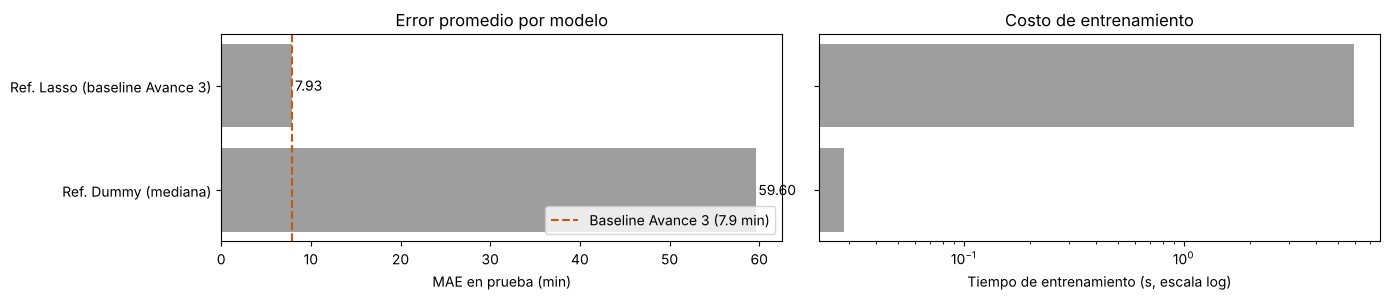

In [6]:
tabla = comparacion.sort_values("MAE_min", ascending=False)
baseline = comparacion.loc["Ref. Lasso (baseline Avance 3)", "MAE_min"]
colores = ["#9e9e9e" if m.startswith("Ref.") else "#1f4e79" for m in tabla.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 0.55 * len(tabla) + 2))

axes[0].barh(tabla.index, tabla["MAE_min"], color=colores)
axes[0].axvline(baseline, color="#c55a11", linestyle="--", label=f"Baseline Avance 3 ({baseline:.1f} min)")
axes[0].set_xlabel("MAE en prueba (min)")
axes[0].set_title("Error promedio por modelo")
axes[0].legend(loc="lower right")
for k, v in enumerate(tabla["MAE_min"]):
    axes[0].text(v + 0.3, k, f"{v:.2f}", va="center")

axes[1].barh(tabla.index, tabla["t_entrenamiento_s"], color=colores)
axes[1].set_xscale("log")
axes[1].set_xlabel("Tiempo de entrenamiento (s, escala log)")
axes[1].set_title("Costo de entrenamiento")
axes[1].set_yticklabels([])

plt.tight_layout()
plt.show()

## 7. Selección de los dos mejores modelos

> **Pendiente.** Elegir los dos modelos alternativos con menor MAE, considerando también RMSE, % dentro de tolerancia, brecha de sobreajuste y tiempo.

## 8. Ajuste fino de hiperparámetros

> **Pendiente.** Búsqueda de hiperparámetros (por ejemplo `RandomizedSearchCV` o `GridSearchCV` con validación cruzada) para los dos modelos seleccionados, comparando el desempeño antes y después del ajuste.

## 9. Modelo individual final

> **Pendiente.** Elección del modelo final con argumentos más allá de la métrica: interpretabilidad, tiempo de entrenamiento y predicción, estabilidad y requisitos de negocio de Feraltar.

## 10. Conclusiones

> **Pendiente.** Conclusiones del avance en el marco de CRISP-ML(Q) y siguientes pasos.

## 11. Bibliografía

- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.
- Visengeriyeva, L., Kammer, A., Bär, I., Kniesz, A., y Plöd, M. (2023). *CRISP-ML(Q). The ML Lifecycle Process*. MLOps. INNOQ. https://ml-ops.org/content/crisp-ml

## 12. Declaración sobre el uso de herramientas de inteligencia artificial

> **Pendiente.** Copiar aquí la declaración del ejemplo proporcionado en la actividad y sustituir el contenido por la información del equipo.